In [3]:
# %%
import numpy as np
import pandas as pd
import xgboost as xgb
from bayes_opt import BayesianOptimization
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

Dataset shape after filtering: (800, 4)
Number of samples per drive cycle:
DC
US06City_extended    400
US06HW_extended      400
Name: count, dtype: int64

Training model...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Train R² Score: 0.8787
Test R² Score: 0.6608
Test RMSE: 0.7817

Finding optimal weights using Bayesian Optimization...
|   iter    |  target   |  log_wPL  |    w1     |    w2     |    w3     |
-------------------------------------------------------------------------
| 1         | 171.5     | -5.876    | 0.9507    | 0.732     | 0.5987    |
| 2         | 167.5     | -6.532    | 0.156     | 0.05808   | 0.8662    |
| 3         | 170.8     | -5.197    | 0.7081    | 0.02058   | 0.9699    |
| 4         | 167.5     | -4.503    | 0.2123    | 0.1818    | 0.1834    |
| 5         | 171.3     | -6.087    | 0.5248    | 0.4319    | 0.2912    |
| 6         | 167.1     | -5.164    | 0.1395    | 0.2921    | 0.3664    |
| 7         | 171.5     | -5.632    | 0.7852    | 0.19

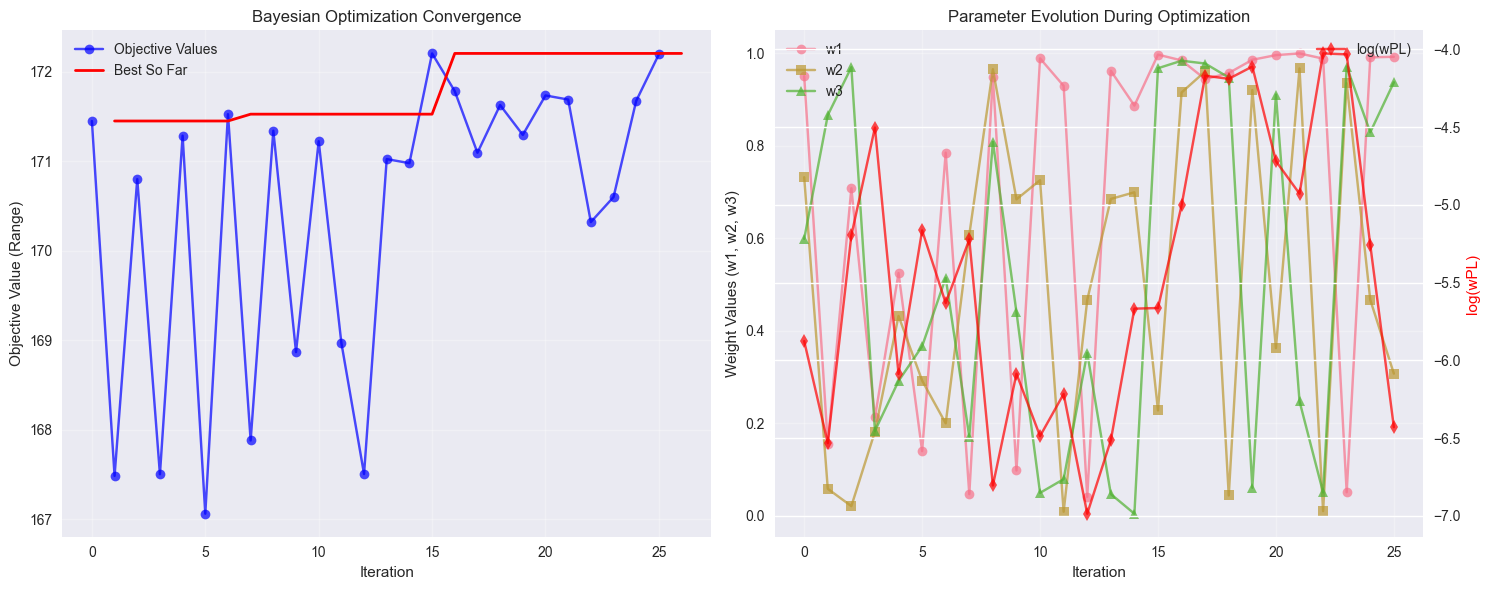

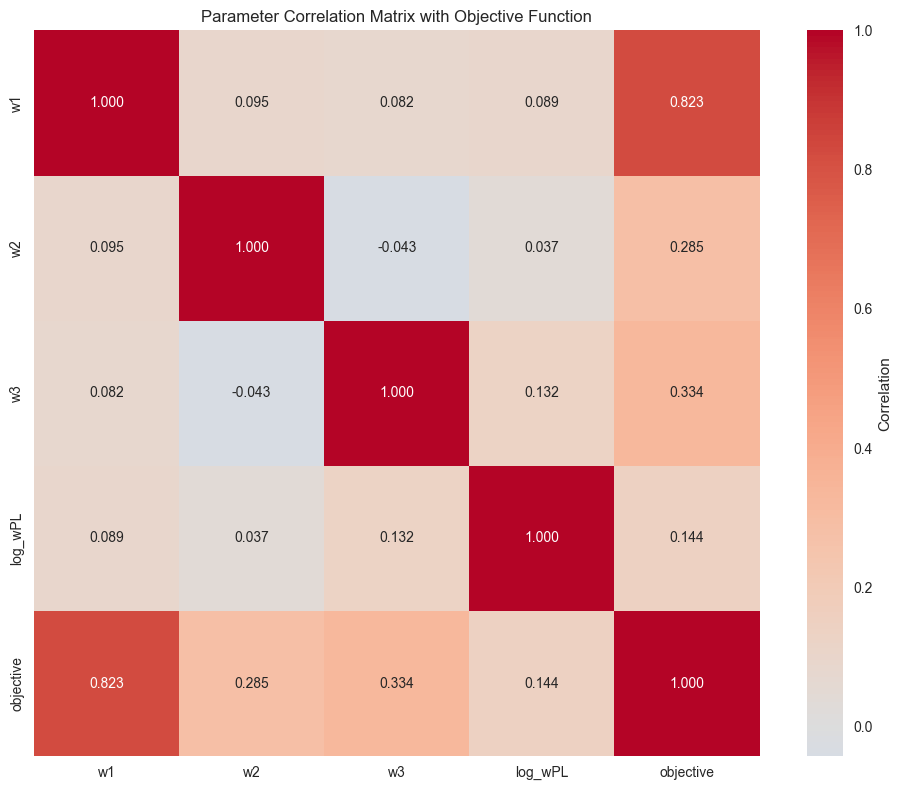

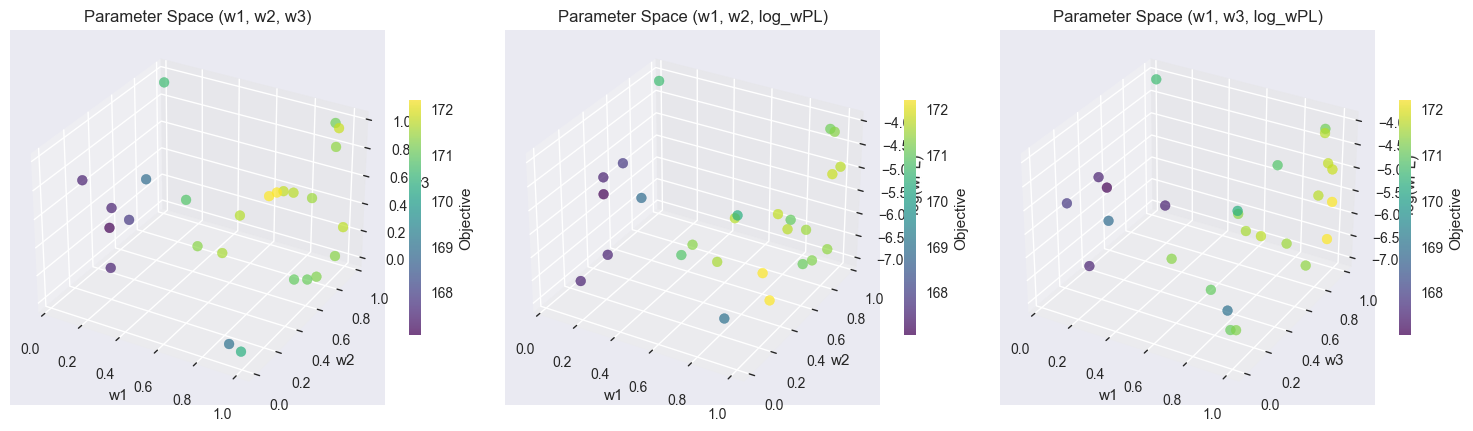

Interactive plot saved as: xgboost_bayesian_interactive.html
Could not display interactive plot in notebook: Mime type rendering requires nbformat>=4.2.0 but it is not installed
Interactive plot has been saved as HTML file instead.

Evaluating optimized weights on each drive cycle...


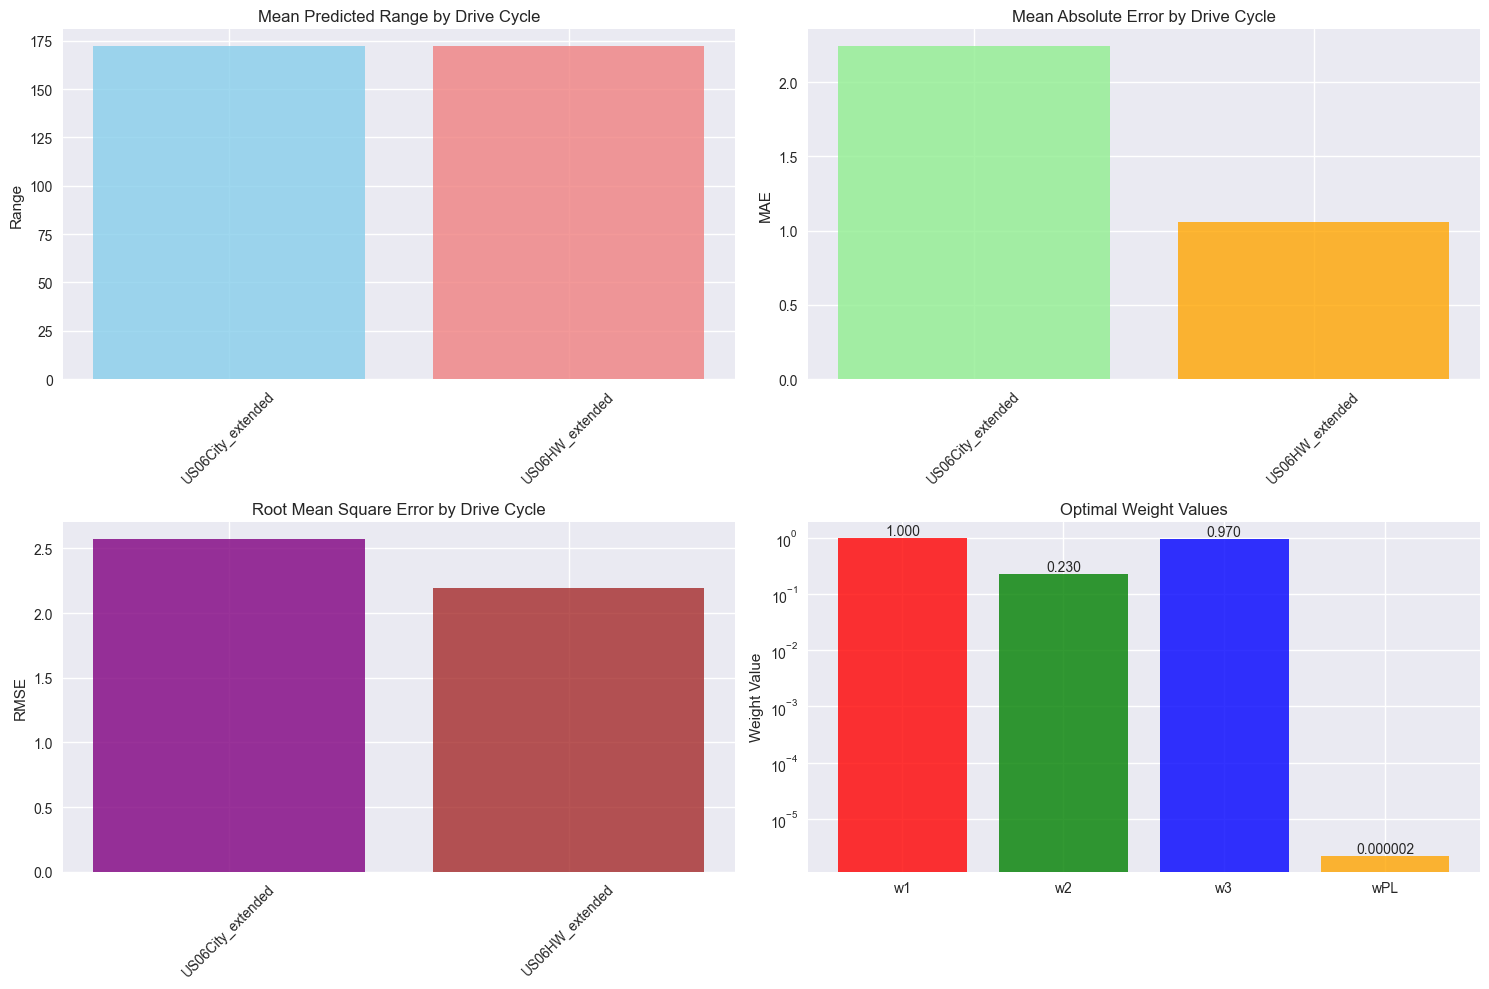


OPTIMAL WEIGHTS FOR COMBINED US DATASET
w1: 1.0
w2: 0.23
w3: 0.97
wPL: 2.2e-06
Predicted optimal range: 172.2050

Performance on individual drive cycles:
                  DC  Mean_Predicted_Range       MAE      RMSE
0  US06City_extended            172.204987  2.242949  2.576053
1    US06HW_extended            172.204987  1.061551  2.190081

All results and visualizations saved with prefix 'xgboost_bayesian'
Files created:
- XGBOOST_Combined_US_Optimal_Weights_with_Viz.csv
- XGBOOST_Combined_US_Evaluation_with_Viz.csv
- XGBOOST_Combined_US_Optimization_History.csv
- xgboost_bayesian_convergence.png
- xgboost_bayesian_correlation.png
- xgboost_bayesian_3d_space.png
- xgboost_bayesian_performance.png
- xgboost_bayesian_interactive.html


In [5]:
# Set style for better plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

def round_weights(weights):
    """Round weights according to specifications."""
    w1, w2, w3 = np.round(weights[:3], 2)
    wPL = np.round(weights[3], 7)
    return np.array([w1, w2, w3, wPL])

def prepare_data(data, selected_dcs=['US06City_extended', 'US06HW_extended']):
    """
    Prepare data for modeling using only the 4 weight features.
    Filters to only include selected drive cycles.
    """
    # Filter to include only the specified drive cycles
    filtered_data = data[data['DC'].isin(selected_dcs)]
    
    # Use only the 4 weight features (no drive cycle)
    X = filtered_data[['w1', 'w2', 'w3', 'wPL']]
    y = filtered_data['range']
    
    return X, y, filtered_data

def train_optimized_model(X, y):
    """
    Train an XGBoost model with hyperparameter tuning using a pipeline.
    """
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('xgb', xgb.XGBRegressor(objective='reg:squarederror', random_state=42))
    ])
    
    param_space = {
        'xgb__max_depth': [3, 4, 5, 6, 7],
        'xgb__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'xgb__n_estimators': [100, 200, 300],
        'xgb__min_child_weight': [1, 3, 5],
        'xgb__subsample': [0.7, 0.8, 0.9, 1.0],
        'xgb__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
        'xgb__gamma': [0, 0.1, 0.2],
        'xgb__reg_alpha': [0, 0.1, 0.5],
        'xgb__reg_lambda': [1, 1.5, 2]
    }
    
    random_search = RandomizedSearchCV(
        pipeline,
        param_space,
        n_iter=30,
        cv=5,
        scoring='neg_mean_squared_error',
        random_state=42,
        verbose=1,
        n_jobs=-1
    )
    
    random_search.fit(X_train, y_train)
    best_pipeline = random_search.best_estimator_
    
    # Evaluate the model
    train_r2 = best_pipeline.score(X_train, y_train)
    test_r2 = best_pipeline.score(X_test, y_test)
    
    print(f"Train R² Score: {train_r2:.4f}")
    print(f"Test R² Score: {test_r2:.4f}")
    
    # Calculate RMSE on test set
    y_pred = best_pipeline.predict(X_test)
    rmse = np.sqrt(np.mean((y_pred - y_test) ** 2))
    print(f"Test RMSE: {rmse:.4f}")
    
    return best_pipeline

class BayesianOptimizationVisualizer:
    """Class to handle Bayesian Optimization with comprehensive visualization."""
    
    def __init__(self, model):
        self.model = model
        self.history = []
        self.best_values = []
        
    def objective_function(self, w1, w2, w3, log_wPL):
        """Objective function for Bayesian Optimization."""
        # Convert log_wPL back to the original scale
        wPL = 10**log_wPL
        weights = np.array([
            np.round(w1, 2),
            np.round(w2, 2),
            np.round(w3, 2),
            np.round(wPL, 7)
        ]).reshape(1, -1)
        
        result = self.model.predict(weights)[0]
        
        # Store history for visualization
        self.history.append({
            'w1': w1, 'w2': w2, 'w3': w3, 'log_wPL': log_wPL, 'wPL': wPL,
            'objective': result, 'iteration': len(self.history)
        })
        
        # Update best values
        if not self.best_values or result > max(self.best_values):
            self.best_values.append(result)
        else:
            self.best_values.append(max(self.best_values))
            
        return result
    
    def optimize(self, init_points=10, n_iter=100, tol=1e-3, patience=10):
        """Run Bayesian Optimization with early stopping."""
        # Define parameter bounds
        pbounds = {
            'w1': (0, 1),
            'w2': (0, 1),
            'w3': (0, 1),
            'log_wPL': (-7, -4)
        }
        
        optimizer = BayesianOptimization(
            f=self.objective_function,
            pbounds=pbounds,
            random_state=42,
            verbose=2
        )
        
        # Run optimization
        optimizer.maximize(init_points=init_points, n_iter=0)
        
        no_improve_count = 0
        current_iter = 0
        prev_best = optimizer.max['target']
        
        while current_iter < n_iter and no_improve_count < patience:
            optimizer.maximize(init_points=0, n_iter=1)
            current_best = optimizer.max['target']
            
            if current_best - prev_best < tol:
                no_improve_count += 1
            else:
                no_improve_count = 0
                
            prev_best = current_best
            current_iter += 1
            
            if current_iter % 5 == 0:
                print(f"Iteration {current_iter}: Best range = {current_best:.4f}, No improvement count: {no_improve_count}")
        
        best_params = optimizer.max['params']
        best_wPL = 10**best_params['log_wPL']
        
        best_weights = np.array([
            np.round(best_params['w1'], 2),
            np.round(best_params['w2'], 2),
            np.round(best_params['w3'], 2),
            np.round(best_wPL, 7)
        ])
        
        best_range = optimizer.max['target']
        
        print(f"\nOptimization completed after {current_iter} iterations")
        print(f"Best weights found: w1={best_weights[0]}, w2={best_weights[1]}, w3={best_weights[2]}, wPL={best_weights[3]}")
        print(f"Predicted range with these weights: {best_range:.4f}")
        
        return best_weights, best_range, optimizer
    
    def plot_convergence(self, save_path=None):
        """Plot convergence of Bayesian Optimization."""
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        
        # Plot objective values over iterations
        iterations = [h['iteration'] for h in self.history]
        objectives = [h['objective'] for h in self.history]
        
        ax1.plot(iterations, objectives, 'bo-', alpha=0.7, label='Objective Values')
        ax1.plot(range(1, len(self.best_values) + 1), self.best_values, 'r-', linewidth=2, label='Best So Far')
        ax1.set_xlabel('Iteration')
        ax1.set_ylabel('Objective Value (Range)')
        ax1.set_title('Bayesian Optimization Convergence')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot parameter evolution
        w1_values = [h['w1'] for h in self.history]
        w2_values = [h['w2'] for h in self.history]
        w3_values = [h['w3'] for h in self.history]
        log_wPL_values = [h['log_wPL'] for h in self.history]
        
        ax2.plot(iterations, w1_values, 'o-', label='w1', alpha=0.7)
        ax2.plot(iterations, w2_values, 's-', label='w2', alpha=0.7)
        ax2.plot(iterations, w3_values, '^-', label='w3', alpha=0.7)
        ax2_twin = ax2.twinx()
        ax2_twin.plot(iterations, log_wPL_values, 'd-', color='red', label='log(wPL)', alpha=0.7)
        
        ax2.set_xlabel('Iteration')
        ax2.set_ylabel('Weight Values (w1, w2, w3)')
        ax2_twin.set_ylabel('log(wPL)', color='red')
        ax2.set_title('Parameter Evolution During Optimization')
        ax2.legend(loc='upper left')
        ax2_twin.legend(loc='upper right')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(f'{save_path}_convergence.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    def plot_parameter_correlation_heatmap(self, save_path=None):
        """Plot correlation heatmap of parameters and objective."""
        df_history = pd.DataFrame(self.history)
        
        # Select relevant columns for correlation
        corr_data = df_history[['w1', 'w2', 'w3', 'log_wPL', 'objective']]
        correlation_matrix = corr_data.corr()
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                   square=True, fmt='.3f', cbar_kws={'label': 'Correlation'})
        plt.title('Parameter Correlation Matrix with Objective Function')
        plt.tight_layout()
        
        if save_path:
            plt.savefig(f'{save_path}_correlation.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    def plot_3d_parameter_space(self, save_path=None):
        """Create 3D visualization of parameter space exploration."""
        df_history = pd.DataFrame(self.history)
        
        fig = plt.figure(figsize=(15, 5))
        
        # 3D plot 1: w1, w2, w3
        ax1 = fig.add_subplot(131, projection='3d')
        scatter = ax1.scatter(df_history['w1'], df_history['w2'], df_history['w3'], 
                             c=df_history['objective'], cmap='viridis', s=50, alpha=0.7)
        ax1.set_xlabel('w1')
        ax1.set_ylabel('w2')
        ax1.set_zlabel('w3')
        ax1.set_title('Parameter Space (w1, w2, w3)')
        plt.colorbar(scatter, ax=ax1, shrink=0.5, label='Objective')
        
        # 3D plot 2: w1, w2, log_wPL
        ax2 = fig.add_subplot(132, projection='3d')
        scatter2 = ax2.scatter(df_history['w1'], df_history['w2'], df_history['log_wPL'], 
                              c=df_history['objective'], cmap='viridis', s=50, alpha=0.7)
        ax2.set_xlabel('w1')
        ax2.set_ylabel('w2')
        ax2.set_zlabel('log(wPL)')
        ax2.set_title('Parameter Space (w1, w2, log_wPL)')
        plt.colorbar(scatter2, ax=ax2, shrink=0.5, label='Objective')
        
        # 3D plot 3: w1, w3, log_wPL
        ax3 = fig.add_subplot(133, projection='3d')
        scatter3 = ax3.scatter(df_history['w1'], df_history['w3'], df_history['log_wPL'], 
                              c=df_history['objective'], cmap='viridis', s=50, alpha=0.7)
        ax3.set_xlabel('w1')
        ax3.set_ylabel('w3')
        ax3.set_zlabel('log(wPL)')
        ax3.set_title('Parameter Space (w1, w3, log_wPL)')
        plt.colorbar(scatter3, ax=ax3, shrink=0.5, label='Objective')
        
        plt.tight_layout()
        if save_path:
            plt.savefig(f'{save_path}_3d_space.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    def plot_interactive_exploration(self, save_path=None):
        """Create interactive Plotly visualization of optimization process."""
        try:
            df_history = pd.DataFrame(self.history)
            
            # Create subplots
            fig = make_subplots(
                rows=2, cols=2,
                subplot_titles=('Convergence Plot', 'Parameter Evolution', 
                              '3D Parameter Space', 'Objective Distribution'),
                specs=[[{"secondary_y": False}, {"secondary_y": True}],
                       [{"type": "scatter3d"}, {"type": "histogram"}]]
            )
            
            # Convergence plot
            fig.add_trace(
                go.Scatter(x=df_history['iteration'], y=df_history['objective'],
                          mode='markers+lines', name='Objective Values',
                          line=dict(color='blue')),
                row=1, col=1
            )
            fig.add_trace(
                go.Scatter(x=list(range(1, len(self.best_values) + 1)), y=self.best_values,
                          mode='lines', name='Best So Far',
                          line=dict(color='red', width=3)),
                row=1, col=1
            )
            
            # Parameter evolution
            fig.add_trace(
                go.Scatter(x=df_history['iteration'], y=df_history['w1'],
                          mode='lines', name='w1', line=dict(color='green')),
                row=1, col=2
            )
            fig.add_trace(
                go.Scatter(x=df_history['iteration'], y=df_history['w2'],
                          mode='lines', name='w2', line=dict(color='orange')),
                row=1, col=2
            )
            fig.add_trace(
                go.Scatter(x=df_history['iteration'], y=df_history['w3'],
                          mode='lines', name='w3', line=dict(color='purple')),
                row=1, col=2
            )
            
            # 3D scatter plot
            fig.add_trace(
                go.Scatter3d(x=df_history['w1'], y=df_history['w2'], z=df_history['w3'],
                            mode='markers',
                            marker=dict(color=df_history['objective'], colorscale='Viridis',
                                      size=8, showscale=True, colorbar=dict(x=0.85, y=0.3)),
                            name='Parameter Space',
                            text=[f"Iter: {i}<br>Obj: {obj:.4f}" 
                                 for i, obj in zip(df_history['iteration'], df_history['objective'])]),
                row=2, col=1
            )
            
            # Objective distribution
            fig.add_trace(
                go.Histogram(x=df_history['objective'], nbinsx=20, name='Objective Distribution',
                            marker_color='lightblue', opacity=0.7),
                row=2, col=2
            )
            
            # Update layout
            fig.update_layout(height=800, showlegend=True, 
                             title_text="Bayesian Optimization Interactive Dashboard")
            
            # Update axes labels
            fig.update_xaxes(title_text="Iteration", row=1, col=1)
            fig.update_yaxes(title_text="Objective Value", row=1, col=1)
            fig.update_xaxes(title_text="Iteration", row=1, col=2)
            fig.update_yaxes(title_text="Parameter Value", row=1, col=2)
            fig.update_xaxes(title_text="Objective Value", row=2, col=2)
            fig.update_yaxes(title_text="Count", row=2, col=2)
            
            # Save HTML file (skip showing in notebook to avoid display issues)
            if save_path:
                fig.write_html(f'{save_path}_interactive.html')
                print(f"Interactive plot saved as: {save_path}_interactive.html")
            
            # Try to show the plot, but handle potential display issues
            try:
                fig.show()
            except Exception as display_error:
                print(f"Could not display interactive plot in notebook: {display_error}")
                print("Interactive plot has been saved as HTML file instead.")
                
        except Exception as e:
            print(f"Error creating interactive visualization: {e}")
            print("Skipping interactive plot generation.")

def predict_range_for_both_dcs(model, weights, data, dcs=['US06City_extended', 'US06HW_extended']):
    """
    Predict range for the given weights on each drive cycle separately and calculate statistics.
    """
    results = []
    
    for dc in dcs:
        # Filter data for this drive cycle
        dc_data = data[data['DC'] == dc]
        
        # Extract actual ranges for comparison
        actual_ranges = dc_data['range'].values
        
        # Create a dataset with the optimized weights
        X_pred = np.tile(weights, (len(dc_data), 1))
        
        # Predict ranges
        predicted_ranges = model.predict(X_pred)
        
        # Calculate error metrics
        mae = np.mean(np.abs(predicted_ranges - actual_ranges))
        rmse = np.sqrt(np.mean((predicted_ranges - actual_ranges) ** 2))
        mean_range = np.mean(predicted_ranges)
        
        results.append({
            'DC': dc,
            'Mean_Predicted_Range': mean_range,
            'MAE': mae,
            'RMSE': rmse
        })
    
    return pd.DataFrame(results)

def plot_model_performance(results, save_path=None):
    """Plot model performance visualization."""
    evaluation_df = results['evaluation']
    
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
    
    # Bar plot of mean predicted ranges
    ax1.bar(evaluation_df['DC'], evaluation_df['Mean_Predicted_Range'], 
           color=['skyblue', 'lightcoral'], alpha=0.8)
    ax1.set_title('Mean Predicted Range by Drive Cycle')
    ax1.set_ylabel('Range')
    ax1.tick_params(axis='x', rotation=45)
    
    # MAE comparison
    ax2.bar(evaluation_df['DC'], evaluation_df['MAE'], 
           color=['lightgreen', 'orange'], alpha=0.8)
    ax2.set_title('Mean Absolute Error by Drive Cycle')
    ax2.set_ylabel('MAE')
    ax2.tick_params(axis='x', rotation=45)
    
    # RMSE comparison
    ax3.bar(evaluation_df['DC'], evaluation_df['RMSE'], 
           color=['purple', 'brown'], alpha=0.8)
    ax3.set_title('Root Mean Square Error by Drive Cycle')
    ax3.set_ylabel('RMSE')
    ax3.tick_params(axis='x', rotation=45)
    
    # Optimal weights visualization
    weights = results['best_weights']
    weight_names = ['w1', 'w2', 'w3', 'wPL']
    colors = ['red', 'green', 'blue', 'orange']
    
    bars = ax4.bar(weight_names, weights, color=colors, alpha=0.8)
    ax4.set_title('Optimal Weight Values')
    ax4.set_ylabel('Weight Value')
    ax4.set_yscale('log')  # Log scale for wPL
    
    # Add value labels on bars
    for bar, weight in zip(bars, weights):
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height,
                f'{weight:.6f}' if weight < 0.01 else f'{weight:.3f}',
                ha='center', va='bottom', fontsize=10)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(f'{save_path}_performance.png', dpi=300, bbox_inches='tight')
    plt.show()

def find_single_optimal_weights_with_viz(data, save_plots=True, plot_prefix='bayesian_opt'):
    """
    Main function: prepare data, train model, and find optimal weights with comprehensive visualization.
    """
    # Prepare data
    X, y, filtered_data = prepare_data(data)
    
    print(f"Dataset shape after filtering: {X.shape}")
    print(f"Number of samples per drive cycle:")
    print(filtered_data['DC'].value_counts())
    
    # Train the model
    print("\nTraining model...")
    model = train_optimized_model(X, y)
    
    # Initialize Bayesian Optimization with visualization
    print("\nFinding optimal weights using Bayesian Optimization...")
    bo_viz = BayesianOptimizationVisualizer(model)
    
    # Run optimization
    best_weights, best_range, optimizer = bo_viz.optimize(init_points=10, n_iter=50)
    
    # Create all visualizations
    if save_plots:
        print("\nGenerating visualizations...")
        try:
            bo_viz.plot_convergence(save_path=plot_prefix)
            bo_viz.plot_parameter_correlation_heatmap(save_path=plot_prefix)
            bo_viz.plot_3d_parameter_space(save_path=plot_prefix)
            bo_viz.plot_interactive_exploration(save_path=plot_prefix)
        except Exception as e:
            print(f"Warning: Some visualizations failed to generate: {e}")
            print("Continuing with optimization results...")
    
    # Evaluate the optimized weights on each drive cycle
    print("\nEvaluating optimized weights on each drive cycle...")
    evaluation = predict_range_for_both_dcs(model, best_weights, filtered_data)
    
    results = {
        'best_weights': best_weights,
        'best_range': best_range,
        'model': model,
        'evaluation': evaluation,
        'filtered_data': filtered_data,
        'optimizer': optimizer,
        'bo_visualizer': bo_viz
    }
    
    # Plot model performance
    if save_plots:
        try:
            plot_model_performance(results, save_path=plot_prefix)
        except Exception as e:
            print(f"Warning: Performance plots failed to generate: {e}")
    
    return results

# %%
# === Main Execution ===
if __name__ == '__main__':
    # Read your dataset (ensure the CSV path is correct)
    data = pd.read_csv('./Version_2_Combined_DataSet.csv')
    
    # Train the model and find optimal weights with comprehensive visualization
    results = find_single_optimal_weights_with_viz(data, save_plots=True, plot_prefix='xgboost_bayesian')
    
    # Display results
    best_weights = results['best_weights']
    print("\n" + "="*60)
    print("OPTIMAL WEIGHTS FOR COMBINED US DATASET")
    print("="*60)
    print(f"w1: {best_weights[0]}")
    print(f"w2: {best_weights[1]}")
    print(f"w3: {best_weights[2]}")
    print(f"wPL: {best_weights[3]}")
    print(f"Predicted optimal range: {results['best_range']:.4f}")
    
    print("\nPerformance on individual drive cycles:")
    print(results['evaluation'])
    
    # Save results to CSV files
    results_df = pd.DataFrame({
        'w1': [best_weights[0]],
        'w2': [best_weights[1]],
        'w3': [best_weights[2]],
        'wPL': [f"{best_weights[3]:.10f}"],
        'predicted_range': [results['best_range']]
    })
    
    results_df.to_csv('XGBOOST_Combined_US_Optimal_Weights_with_Viz.csv', index=False)
    results['evaluation'].to_csv('XGBOOST_Combined_US_Evaluation_with_Viz.csv', index=False)
    
    # Save optimization history
    history_df = pd.DataFrame(results['bo_visualizer'].history)
    history_df.to_csv('XGBOOST_Combined_US_Optimization_History.csv', index=False)
    
    print(f"\nAll results and visualizations saved with prefix 'xgboost_bayesian'")
    print("Files created:")
    print("- XGBOOST_Combined_US_Optimal_Weights_with_Viz.csv")
    print("- XGBOOST_Combined_US_Evaluation_with_Viz.csv") 
    print("- XGBOOST_Combined_US_Optimization_History.csv")
    print("- xgboost_bayesian_convergence.png")
    print("- xgboost_bayesian_correlation.png")
    print("- xgboost_bayesian_3d_space.png")
    print("- xgboost_bayesian_performance.png")
    print("- xgboost_bayesian_interactive.html")